In [1]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [2]:
import requests
import pandas as pd
 
BASE = "https://data-api.binance.vision/api/v3"
 
# ─────────────────────────────────────────────
# 1) KLINES — 90 days of hourly OHLCV (the time series)
# ─────────────────────────────────────────────
end_ms = int(pd.Timestamp.now(tz="UTC").timestamp() * 1000)
start_ms = end_ms - 90 * 24 * 3600 * 1000
 
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "num_trades",
    "taker_buy_base", "taker_buy_quote", "ignore"
]
 
rows = []
while start_ms < end_ms:
    params = {"symbol": "BTCUSDT", "interval": "1h",
              "startTime": start_ms, "endTime": end_ms, "limit": 1000}
    data = requests.get(f"{BASE}/klines", params=params).json()
    if not isinstance(data, list) or not data:
        break
    rows.extend(data)
    start_ms = data[-1][0] + 1
 
df = pd.DataFrame(rows, columns=columns)
df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")
df["close_time"] = pd.to_datetime(df["close_time"], unit="ms")
for col in ["open", "high", "low", "close", "volume", "quote_volume"]:
    df[col] = df[col].astype(float)
df["num_trades"] = df["num_trades"].astype(int)
df = df[["open_time", "open", "high", "low", "close", "volume", "num_trades"]]
 
# ─────────────────────────────────────────────
# 2) DEPTH — a snapshot of the order book RIGHT NOW
# ─────────────────────────────────────────────
depth = requests.get(f"{BASE}/depth",
                     params={"symbol": "BTCUSDT", "limit": 100}).json()
depth_df = pd.DataFrame({
    "bid_price":   [float(b[0]) for b in depth["bids"]],
    "bid_qty":     [float(b[1]) for b in depth["bids"]],
    "ask_price":   [float(a[0]) for a in depth["asks"]],
    "ask_qty":     [float(a[1]) for a in depth["asks"]],
    "last_update_id": depth["lastUpdateId"],
})
 
# ─────────────────────────────────────────────
# 3) AGGTRADES — recent aggregated trades (last ~1000)
# ─────────────────────────────────────────────
trades = requests.get(f"{BASE}/aggTrades",
                      params={"symbol": "BTCUSDT", "limit": 1000}).json()
trades_df = pd.DataFrame(trades)
trades_df["T"] = pd.to_datetime(trades_df["T"], unit="ms")
trades_df["p"] = trades_df["p"].astype(float)
trades_df["q"] = trades_df["q"].astype(float)
 
# ─────────────────────────────────────────────
# 4) EXCHANGEINFO — static metadata for BTCUSDT
# ─────────────────────────────────────────────
info = requests.get(f"{BASE}/exchangeInfo").json()
btc = [s for s in info["symbols"] if s["symbol"] == "BTCUSDT"][0]



(               open_time      open      high       low     close      volume  \
 0    2026-05-10 17:00:00  81378.25  81583.11  81220.00  81476.18   599.74468   
 1    2026-05-10 18:00:00  81476.18  81493.11  81231.14  81271.96   268.90805   
 2    2026-05-10 19:00:00  81271.96  81481.92  81148.00  81437.83   334.34752   
 3    2026-05-10 20:00:00  81437.83  81459.66  80279.77  80734.88  1021.73969   
 4    2026-05-10 21:00:00  80734.88  80944.44  80571.97  80720.47   691.73163   
 ...                  ...       ...       ...       ...       ...         ...   
 2155 2026-08-08 12:00:00  64967.36  65050.55  64924.00  65008.34   234.45077   
 2156 2026-08-08 13:00:00  65008.33  65018.00  65000.00  65015.27   187.85749   
 2157 2026-08-08 14:00:00  65015.27  65192.54  65015.27  65129.02   356.35929   
 2158 2026-08-08 15:00:00  65129.01  65149.57  65061.31  65080.82   186.58480   
 2159 2026-08-08 16:00:00  65080.83  65116.82  65080.82  65091.05    22.23672   
 
       num_trades  
 0    

In [4]:
trades_df

,a,p,q,f,l,T,m,M
0,4030895696,65091.60,0.00307,6564297601,6564297614,2026-08-08 16:08:04.690,False,True
1,4030895697,65091.59,0.01537,6564297615,6564297615,2026-08-08 16:08:06.599,True,True
2,4030895698,65091.59,0.00009,6564297616,6564297616,2026-08-08 16:08:07.266,True,True
3,4030895699,65091.59,0.00460,6564297617,6564297617,2026-08-08 16:08:07.316,True,True
4,4030895700,65091.60,0.00010,6564297618,6564297619,2026-08-08 16:08:07.517,False,True
...,...,...,...,...,...,...,...,...
995,4030896691,65091.04,0.00057,6564300948,6564300948,2026-08-08 16:13:41.764,True,True
996,4030896692,65091.05,0.00076,6564300949,6564300949,2026-08-08 16:13:42.047,False,True
997,4030896693,65091.04,0.00465,6564300950,6564300950,2026-08-08 16:13:42.160,True,True
998,4030896694,65091.05,0.14748,6564300951,6564300954,2026-08-08 16:13:43.117,False,True


In [8]:
import numpy as np

df["log_return"] = np.log(df["close"] / df["close"].shift(1))

df["log_return_lag1"] = df["log_return"].shift(1)
df["log_return_lag2"] = df["log_return"].shift(2)

df["volatility_6"] = df["log_return"].rolling(6).std() * np.sqrt(6)
df["volatility_12"] = df["log_return"].rolling(12).std() * np.sqrt(12)
df["volatility_24"] = df["log_return"].rolling(24).std() * np.sqrt(24)

df["volume_change"] = df["volume"].pct_change()
df["ema_12"] = df["close"].ewm(span=12, adjust=False).mean()
df["ema_distance"] = df["close"] - df["ema_12"]

period = 14

delta = df["close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1/period, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/period, adjust=False).mean()

rs = avg_gain / avg_loss
df["rsi_14"] = 100 - (100 / (1 + rs))
ema_26 = df["close"].ewm(span=26, adjust=False).mean()

df["macd"] = df["ema_12"] - ema_26
df["macd_signal"] = df["macd"].ewm(span=9, adjust=False).mean()
df["macd_hist"] = df["macd"] - df["macd_signal"]
df["sma_ret_20"] = df["log_return"].rolling(20).mean()

# target: realized volatility over the next 12 bars
horizon = 12
df["vol_target"] = (
    df["log_return"].shift(-horizon).rolling(horizon).std() * np.sqrt(horizon)
)

df = df.dropna().reset_index(drop=True)
df.columns

Index(['open_time', 'open', 'high', 'low', 'close', 'volume', 'num_trades',
       'log_return', 'log_return_lag1', 'log_return_lag2', 'volatility_6',
       'volatility_12', 'volatility_24', 'volume_change', 'ema_12',
       'ema_distance', 'rsi_14', 'macd', 'macd_signal', 'macd_hist',
       'sma_ret_20', 'vol_target'],
      dtype='str')

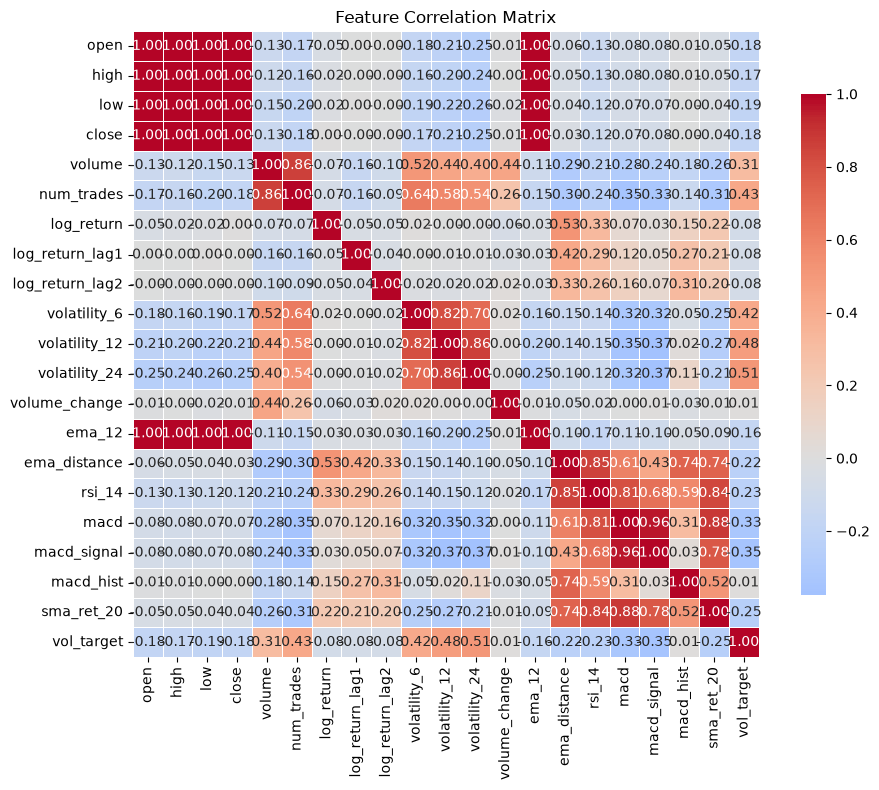

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix (only numeric columns, drop timestamp)
corr = df.drop(columns=['open_time']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [7]:
df

,open_time,open,high,low,close,volume,num_trades,log_return,log_return_lag1,log_return_lag2,...,volatility_24,volume_change,ema_12,ema_distance,rsi_14,macd,macd_signal,macd_hist,sma_ret_20,vol_target
0,2026-05-11 17:00:00,81575.84,82071.77,81369.42,81941.09,565.28919,130148,0.004467,0.001594,0.006066,...,0.024242,-0.492317,81286.602182,654.487818,54.285947,38.649308,-67.036817,105.686124,0.000750,0.006212
1,2026-05-11 18:00:00,81941.09,82137.26,81836.15,81858.96,536.09834,122807,-0.001003,0.004467,0.001594,...,0.024110,-0.051639,81374.657231,484.302769,52.758490,81.444570,-37.340539,118.785109,-0.000113,0.006455
2,2026-05-11 19:00:00,81858.97,82091.11,81739.09,81961.99,458.60970,99644,0.001258,-0.001003,0.004467,...,0.024064,-0.144542,81465.016118,496.973882,54.488502,122.264395,-5.419552,127.683948,-0.000151,0.006094
3,2026-05-11 20:00:00,81961.99,82078.91,81758.50,81821.02,322.40099,80962,-0.001721,0.001258,-0.001003,...,0.022311,-0.297004,81519.785946,301.234054,51.698827,141.606943,23.985747,117.621197,0.000214,0.006111
4,2026-05-11 21:00:00,81821.03,81906.35,81600.00,81821.18,268.82965,71491,0.000002,-0.001721,0.001258,...,0.022305,-0.166164,81566.154262,255.025738,51.701849,155.160371,50.220671,104.939699,0.000196,0.006097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2119,2026-08-08 00:00:00,64923.20,64954.00,64784.19,64929.01,432.59470,25634,0.000090,0.000542,-0.000616,...,0.009921,0.664271,64879.242859,49.767141,56.909202,96.883475,98.857740,-1.974265,0.000522,0.002231
2120,2026-08-08 01:00:00,64929.01,64965.00,64908.97,64911.79,283.12303,22019,-0.000265,0.000090,0.000542,...,0.009856,-0.345524,64884.250111,27.539889,56.035080,92.303274,97.546847,-5.243572,0.000445,0.002195
2121,2026-08-08 02:00:00,64911.80,64957.47,64894.49,64923.97,317.46111,21324,0.000188,-0.000265,0.000090,...,0.009833,0.121283,64890.360863,33.609137,56.543524,88.634533,95.764384,-7.129851,0.000480,0.002727
2122,2026-08-08 03:00:00,64923.98,65074.18,64918.28,65033.00,277.39242,27377,0.001678,0.000188,-0.000265,...,0.009679,-0.126216,64912.305346,120.694654,60.902361,93.447633,95.301034,-1.853401,0.000551,0.002412


In [43]:
# ── volatility prediction setup: features + future realized-vol target ─────────────────
feature_cols = [
    "log_return_lag2",
    "log_return_lag1",
    "volatility_6",
    "volatility_12",
    "volatility_24",
    "volume_change",
    "ema_distance",
    "rsi_14",
    "macd_hist",
    "sma_ret_20"
]

TARGET = "vol_target"

# Build X and y separately
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)

# ── time-based split ─────────────────────────────────────────────────
train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train_full = X[:train_end]
X_val_full = X[train_end:val_end]
X_test_full = X[val_end:]

y_train_full = y[:train_end]
y_val_full = y[train_end:val_end]
y_test_full = y[val_end:]

# Fit normalization on training set only
feature_mean = X_train_full.mean(axis=0)
feature_std = X_train_full.std(axis=0)
feature_std[feature_std == 0] = 1.0

X_train = (X_train_full - feature_mean) / feature_std
X_val = (X_val_full - feature_mean) / feature_std
X_test = (X_test_full - feature_mean) / feature_std

# normalize target too, but separately
# this keeps the regression model stable and interpretable
target_mean = y_train_full.mean()
target_std = y_train_full.std()
if target_std == 0:
    target_std = 1.0

y_train = (y_train_full - target_mean) / target_std
y_val = (y_val_full - target_mean) / target_std
y_test = (y_test_full - target_mean) / target_std

# ── sequence windows: X[t-window:t], y[t] ───────────────────────────
def make_windows(X_seq, y_seq, seq_len=10):
    Xw, yw = [], []
    for i in range(len(X_seq) - seq_len):
        Xw.append(X_seq[i:i + seq_len])
        yw.append(y_seq[i + seq_len])
    return np.asarray(Xw, dtype=np.float32), np.asarray(yw, dtype=np.float32)

X_train, y_train = make_windows(X_train, y_train, seq_len=10)
X_val, y_val = make_windows(X_val, y_val, seq_len=10)
X_test, y_test = make_windows(X_test, y_test, seq_len=10)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("first target samples:", y_train[:5])

X_train: (1451, 10, 10)  y_train: (1451,)
first target samples: [-0.01539203  0.11605027  0.30761692  0.32799017  0.3276523 ]


In [44]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [45]:
class Model(nn.Module):
    def __init__(self, input_size, hidden_size=8, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        return self.head(out)

In [46]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

In [66]:
model = Model(X_train.shape[-1], hidden_size=8, num_layers=1,dropout=0.3)
model

Model(
  (lstm): LSTM(10, 8, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (head): Linear(in_features=8, out_features=1, bias=True)
)

Epoch 1/500 - train_loss: 0.365139 - val_loss: 0.372056
Epoch 2/500 - train_loss: 0.362911 - val_loss: 0.361554
Epoch 3/500 - train_loss: 0.364426 - val_loss: 0.351211
Epoch 4/500 - train_loss: 0.354145 - val_loss: 0.341381
Epoch 5/500 - train_loss: 0.350157 - val_loss: 0.331882
Epoch 6/500 - train_loss: 0.345368 - val_loss: 0.322021
Epoch 7/500 - train_loss: 0.338464 - val_loss: 0.313040
Epoch 8/500 - train_loss: 0.340573 - val_loss: 0.304374
Epoch 9/500 - train_loss: 0.331735 - val_loss: 0.295597
Epoch 10/500 - train_loss: 0.328594 - val_loss: 0.287139
Epoch 11/500 - train_loss: 0.327205 - val_loss: 0.279118
Epoch 12/500 - train_loss: 0.321565 - val_loss: 0.271684
Epoch 13/500 - train_loss: 0.324264 - val_loss: 0.264306
Epoch 14/500 - train_loss: 0.318251 - val_loss: 0.257158
Epoch 15/500 - train_loss: 0.322454 - val_loss: 0.250579
Epoch 16/500 - train_loss: 0.315976 - val_loss: 0.244683
Epoch 17/500 - train_loss: 0.317062 - val_loss: 0.238771
Epoch 18/500 - train_loss: 0.312293 - va

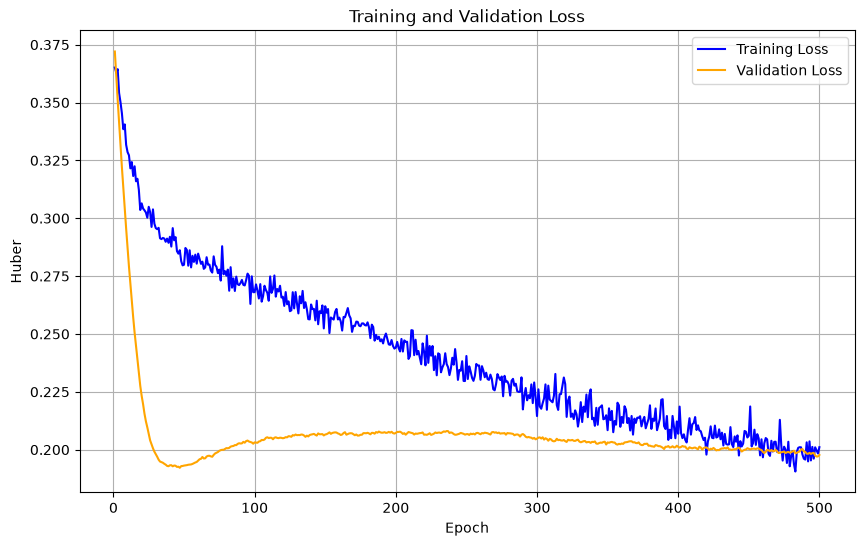

In [67]:
import matplotlib.pyplot as plt

learning_rate = 1e-4
num_epochs = 500
criterion = nn.HuberLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Huber")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [68]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.132221


In [23]:
# --- 1. Gather ALL model predictions + targets on the test set ---
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for feature, label in test_data_loader:
        preds.append(model(feature).squeeze(-1))
        actuals.append(label)
preds = torch.cat(preds)
actuals = torch.cat(actuals)

# --- 2. Mean baseline: predict the mean of the TRAINING target ---
baseline_value = y_train.mean()
baseline_preds = torch.full_like(actuals, float(baseline_value))

# --- 3. Evaluate both with identical metrics ---
def report(pred, target, name):
    mse = ((pred - target) ** 2).mean()
    mae = (pred - target).abs().mean()
    rmse = mse.sqrt()
    print(f"{name:>16} | RMSE: {rmse:.6f} | MAE: {mae:.6f}")

print("NORMALIZED log-return space:")
report(preds, actuals, "Model")
report(baseline_preds, actuals, "Mean baseline")

# --- 4. Undo the target scaling to real log-return space ---
pred_lr = preds * target_std + target_mean
base_lr = baseline_preds * target_std + target_mean
actual_lr = actuals * target_std + target_mean

print("\nREAL log-return space:")
report(pred_lr, actual_lr, "Model")
report(base_lr, actual_lr, "Mean baseline")

print(f"\nBaseline predicts: {float(baseline_value):.6f} (normalized)")
print(f"                 = {float(base_lr[0]):.6f} log return")


NORMALIZED log-return space:
           Model | RMSE: 0.606885 | MAE: 0.472848
   Mean baseline | RMSE: 0.739872 | MAE: 0.657762

REAL log-return space:
           Model | RMSE: 0.005189 | MAE: 0.004043
   Mean baseline | RMSE: 0.006326 | MAE: 0.005624

Baseline predicts: 0.004760 (normalized)
                 = 0.014424 log return


In [120]:
#M

In [121]:
'''
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,
    "mean": mean,
    "std": std,
    "price_mean": price_mean,
    "price_std": price_std,
    "training_loss": training_loss,
    "testing_loss": testing_loss,
    "rmse_usd": rmse,
    "mae_usd": mae
}, "bitcoin_lstm_model.pt")

'''

'\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    "learning_rate": learning_rate,\n    "num_epochs": num_epochs,\n    "mean": mean,\n    "std": std,\n    "price_mean": price_mean,\n    "price_std": price_std,\n    "training_loss": training_loss,\n    "testing_loss": testing_loss,\n    "rmse_usd": rmse,\n    "mae_usd": mae\n}, "bitcoin_lstm_model.pt")\n\n'

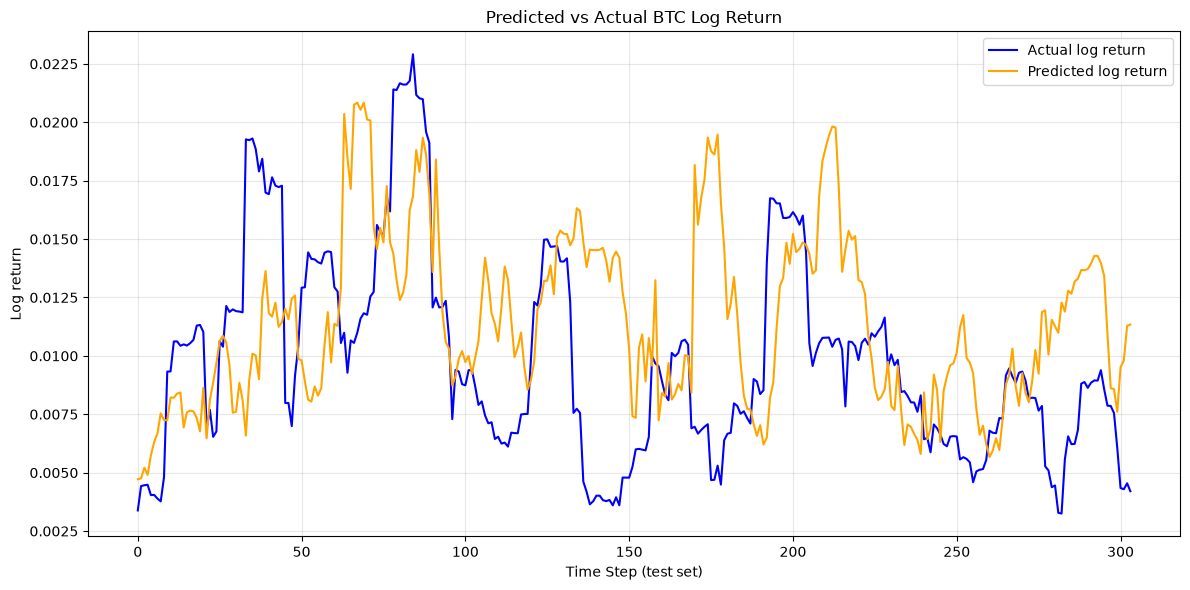

In [69]:
import matplotlib.pyplot as plt

# Convert back to real log return space
pred_logret = preds * target_std + target_mean
actual_logret = actuals * target_std + target_mean

plt.figure(figsize=(12, 6))
plt.plot(actual_logret.numpy(), label="Actual log return", color="blue", linewidth=1.5)
plt.plot(pred_logret.numpy(), label="Predicted log return", color="orange", linewidth=1.5)
plt.xlabel("Time Step (test set)")
plt.ylabel("Log return")
plt.title("Predicted vs Actual BTC Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [123]:
model.eval()

# compare to a simple persistence baseline: last observed value in each input window
all_preds = []
all_true = []
all_prev = []

with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        all_preds.append(pred.cpu().numpy())
        all_true.append(label.cpu().numpy())
        all_prev.append(feature[:, -1, -1].cpu().numpy())

all_preds = np.concatenate(all_preds)
all_true = np.concatenate(all_true)
all_prev = np.concatenate(all_prev)

# restore real target scale for interpretation
pred_lr = all_preds * target_std + target_mean
true_lr = all_true * target_std + target_mean
prev_lr = all_prev * target_std + target_mean

rmse = np.sqrt(np.mean((pred_lr - true_lr) ** 2))
mae = np.mean(np.abs(pred_lr - true_lr))

persist_rmse = np.sqrt(np.mean((prev_lr - true_lr) ** 2))
persist_mae = np.mean(np.abs(prev_lr - true_lr))

beats_persistence = np.mean(np.abs(pred_lr - true_lr) < np.abs(prev_lr - true_lr))

print(f"Model RMSE: {rmse:.6f} | MAE: {mae:.6f}")
print(f"Persistence baseline RMSE: {persist_rmse:.6f} | MAE: {persist_mae:.6f}")
print(f"Model beats persistence on {beats_persistence * 100:.1f}% of test windows")

print("\n  Prev log return | Predicted | Actual")
for p, t, prev in zip(pred_lr[:8], true_lr[:8], prev_lr[:8]):
    print(f"  {prev: .6f}   | {p: .6f} | {t: .6f}")


Model RMSE: 0.003238 | MAE: 0.002287
Persistence baseline RMSE: 0.004545 | MAE: 0.003515
Model beats persistence on 64.0% of test windows

  Prev log return | Predicted | Actual
   0.002161   | -0.000535 |  0.000575
   0.002031   | -0.000139 | -0.000600
   0.002025   |  0.001080 | -0.000719
   0.001281   | -0.000086 |  0.003227
   0.002336   | -0.000752 |  0.008516
   0.004350   | -0.001769 | -0.000194
   0.004175   | -0.000367 | -0.004107
   0.003184   | -0.001069 |  0.001139


said UP,    was UP:   64
said UP,    was DOWN: 68
said DOWN,  was UP:   101
said DOWN,  was DOWN: 78
precision of UP calls: 48.5%   <-- 'when I said up, how often was I right'
base rate (hours that were actually up): 53.1%
overall accuracy: 45.7%


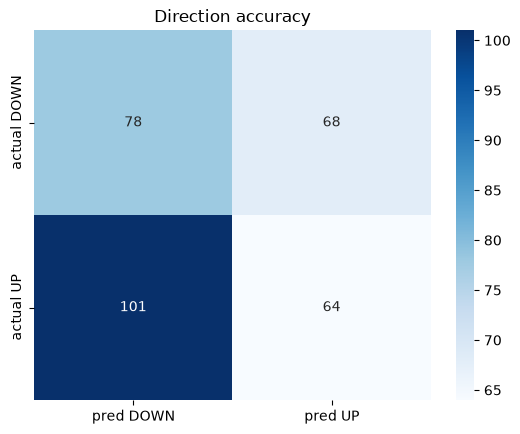

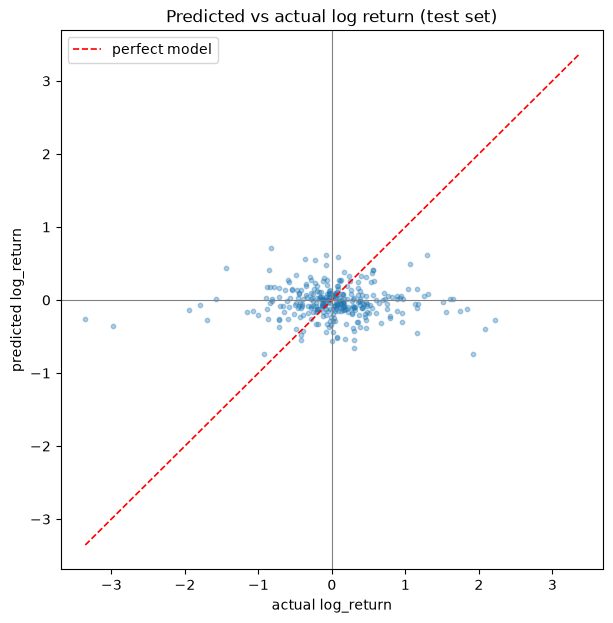

In [124]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
preds = np.asarray(preds)      # your predicted log returns
actuals = np.asarray(actuals)  # your actual log returns
 
pred_up = preds > 0
actual_up = actuals > 0
 
# ── your question, as numbers ──
tp = (pred_up & actual_up).sum()     # said UP   -> was UP
fp = (pred_up & ~actual_up).sum()    # said UP   -> was DOWN
fn = (~pred_up & actual_up).sum()    # said DOWN -> was UP
tn = (~pred_up & ~actual_up).sum()   # said DOWN -> was DOWN
 
print(f"said UP,    was UP:   {tp}")
print(f"said UP,    was DOWN: {fp}")
print(f"said DOWN,  was UP:   {fn}")
print(f"said DOWN,  was DOWN: {tn}")
print(f"precision of UP calls: {tp/(tp+fp):.1%}   <-- 'when I said up, how often was I right'")
print(f"base rate (hours that were actually up): {(actuals > 0).mean():.1%}")
print(f"overall accuracy: {(tp+tn)/len(preds):.1%}")
 
# ── your question, as a picture: confusion matrix ──
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred DOWN", "pred UP"],
            yticklabels=["actual DOWN", "actual UP"])
plt.title("Direction accuracy")
plt.show()
 
# ── the big picture: predicted vs actual ──
plt.figure(figsize=(7, 7))
plt.scatter(actuals, preds, alpha=0.35, s=10)
lim = max(abs(actuals.min()), abs(actuals.max()),
          abs(preds.min()), abs(preds.max()))
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1.2, label="perfect model")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("actual log_return")
plt.ylabel("predicted log_return")
plt.legend()
plt.title("Predicted vs actual log return (test set)")
plt.show()

Real log-return space:
           Model | RMSE: 0.003238 | MAE: 0.002287
     Persistence | RMSE: 0.004545 | MAE: 0.003515


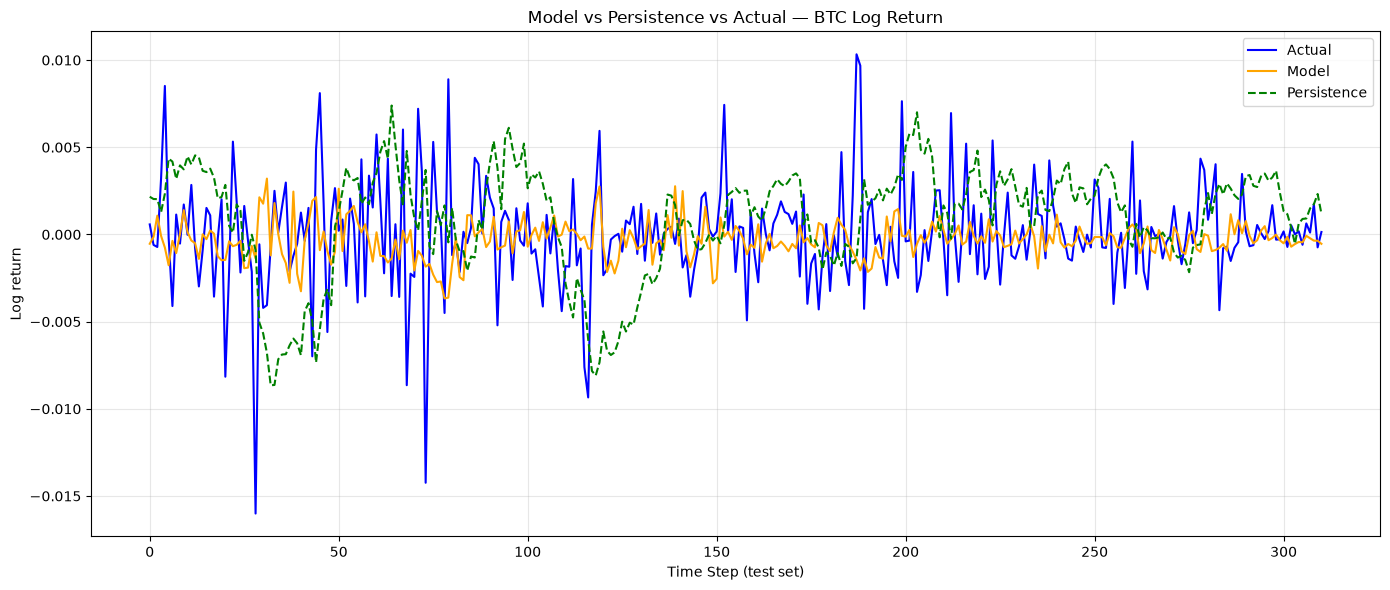

In [128]:
import matplotlib.pyplot as plt

# model predictions in real log-return space
pred_logret = preds * target_std + target_mean
actual_logret = actuals * target_std + target_mean

# persistence baseline: last observed log_return in each window
persist_logret = X_test[:, -1, -1] * target_std + target_mean

# Metrics
def metrics(pred, actual, name):
    rmse = np.sqrt(((pred - actual) ** 2).mean())
    mae = np.abs(pred - actual).mean()
    print(f"{name:>16} | RMSE: {rmse:.6f} | MAE: {mae:.6f}")

print("Real log-return space:")
metrics(np.array(pred_logret), np.array(actual_logret), "Model")
metrics(persist_logret, np.array(actual_logret), "Persistence")

# Plot
plt.figure(figsize=(14, 6))
plt.plot(np.array(actual_logret), label="Actual", color="blue", linewidth=1.5)
plt.plot(np.array(pred_logret), label="Model", color="orange", linewidth=1.5)
plt.plot(persist_logret, label="Persistence", color="green", linewidth=1.5, linestyle="--")
plt.xlabel("Time Step (test set)")
plt.ylabel("Log return")
plt.title("Model vs Persistence vs Actual — BTC Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
